PLEASE REFER TO APPENDIX ON HOW TO RUN THE CODE, CHANGE THE FILE NAMES ACCORDINGLY IN ORDER FOR THE DATASETS TO BE IMPORTED ON YOUR SYSTEM. YOU CAN LOCATE THE WHEREABOUTS OF THE CSV'S BY CHECKING THE PATHWAY WHERE THE CODE IS TRYING TO IMPORT


USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

In [ ]:
df = pd.read_csv(localized_url('/Users/yarkin/Desktop/Dissertation/statistical-analysis-and-modeling-of-football-data/Sofascore/Data/sofa_stats_with_understat_id.csv'))

In [ ]:
understat_index=pd.read_csv(localized_url("/Users/yarkin/Desktop/Dissertation/statistical-analysis-and-modeling-of-football-data/Understat/Data/understat_match_1524.csv"))

In [73]:
understat_index.columns

Index(['id', 'fid', 'h', 'a', 'date', 'league_id', 'season', 'h_goals',
       'a_goals', 'team_h', 'team_a', 'h_xg', 'a_xg', 'h_w', 'h_d', 'h_l',
       'league', 'h_shot', 'a_shot', 'h_shotOnTarget', 'a_shotOnTarget',
       'h_deep', 'a_deep', 'a_ppda', 'h_ppda'],
      dtype='object')

In [74]:
understat_features= ['h_xg', 'a_xg', 'h_w', 'h_d', 'h_l',
       'league', 'h_shot', 'a_shot', 'h_shotOnTarget', 'a_shotOnTarget',
       'h_deep', 'a_deep', 'a_ppda', 'h_ppda']

In [75]:
def pivot_df(df, features):
    home_features = [col for col in df[features] if col.startswith('h_')]
    home_df = df[home_features + ["id", "h", "team_h", "date", "season"]].copy()
    home_df.columns = [col.replace('h_', '') if col in home_features else col for col in home_df.columns]
    home_df.rename(columns={"h": "team_id", "team_h": "team_name"}, inplace=True)
    home_df["h_a"] = "h"

    away_features = [col for col in df[features] if col.startswith('a_')]
    away_df = df[away_features + ["id", "a", "team_a", "date", "season"]].copy()
    away_df.columns = [col.replace('a_', '') if col in away_features else col for col in away_df.columns]
    away_df.rename(columns={"a": "team_id", "team_a": "team_name"}, inplace=True)
    away_df["h_a"] = "a"

    return pd.concat([home_df, away_df], axis=0)

In [76]:
understat_index= pivot_df(understat_index, understat_features)

In [77]:
understat_index

,xg,w,d,l,shot,shotOnTarget,deep,ppda,id,team_id,team_name,date,season,h_a
0,0.627539,0.2859,0.3905,0.3236,9,1,4,13.8261,81,89,Manchester United,2015-08-08 15:45:00,2015,h
1,0.876106,0.3435,0.3607,0.2958,11,2,11,6.9000,82,73,Bournemouth,2015-08-08 18:00:00,2015,h
2,0.604226,0.2988,0.4337,0.2675,10,5,5,6.6500,83,72,Everton,2015-08-08 18:00:00,2015,h
3,2.568030,0.6422,0.2057,0.1521,19,8,5,10.8800,84,75,Leicester,2015-08-08 18:00:00,2015,h
4,1.130760,0.1461,0.2159,0.6380,17,6,5,5.7368,85,79,Norwich,2015-08-08 18:00:00,2015,h
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,0.598846,NaN,NaN,NaN,8,2,0,30.3000,22270,71,Aston Villa,2024-05-19 15:00:00,2023,a
3416,0.731254,NaN,NaN,NaN,4,3,1,16.6000,22271,229,Wolverhampton Wanderers,2024-05-19 15:00:00,2023,a
3417,1.115980,NaN,NaN,NaN,15,7,5,10.5000,22272,228,Fulham,2024-05-19 15:00:00,2023,a
3418,0.240159,NaN,NaN,NaN,3,2,0,63.0000,22273,81,West Ham,2024-05-19 15:00:00,2023,a


In [78]:
df= pd.merge(df, understat_index[["id", "team_name", "team_id", "season"]], how='left', on=["id", "team_id"]);df_pivoted=df.copy()

In [79]:
df.columns

Index(['id', 'sofa_id', 'team_id', 'date', 'Corner kicks', 'Fouls',
       'Shots off target', 'Throw-ins', 'Ground duels', 'Aerial duels',
       'Blocked per shots on target', 'Shots on target per total shots',
       'Hit woodwork per total shots', 'Shots outside box per total shots',
       'Big chances', 'Fouled in final third', 'Tackles won', 'Dribbles',
       'Crosses', 'Long balls', 'Yellow cards', 'Offsides', 'Goalkeeper saves',
       'h_a', 'team_name', 'season'],
      dtype='object')

In [80]:
feature_list = ['Corner kicks', 'Fouls',
       'Shots off target', 'Throw-ins', 'Ground duels', 'Aerial duels',
       'Blocked per shots on target', 'Shots on target per total shots',
       'Hit woodwork per total shots', 'Shots outside box per total shots',
       'Big chances', 'Fouled in final third', 'Tackles won', 'Dribbles',
       'Crosses', 'Long balls', 'Yellow cards', 'Offsides', 'Goalkeeper saves']

In [81]:
team_summaries_seasonal_df = df_pivoted.groupby(['team_id', 'team_name', 'season']).agg({
    feature: "mean" for feature in feature_list
}).reset_index()

In [82]:
team_summaries_seasonal_df

,team_id,team_name,season,Corner kicks,Fouls,Shots off target,Throw-ins,Ground duels,Aerial duels,Blocked per shots on target,...,Shots outside box per total shots,Big chances,Fouled in final third,Tackles won,Dribbles,Crosses,Long balls,Yellow cards,Offsides,Goalkeeper saves
0,71,Aston Villa,2015,4.394737,0.157895,4.394737,23.789474,0.508158,0.535263,1.118484,...,0.463388,1.500000,0.210526,1.000000,0.868421,0.000000,0.289474,2.131579,1.263158,3.052632
1,71,Aston Villa,2019,5.263158,11.868421,4.868421,20.973684,0.513158,0.481842,1.243870,...,0.357060,1.605263,3.131579,0.542105,0.627632,0.229211,0.436579,1.842105,1.710526,3.078947
2,71,Aston Villa,2020,5.605263,11.552632,4.973684,20.526316,0.531053,0.518158,1.104854,...,0.350506,2.078947,3.421053,0.540789,0.616053,0.237368,0.465000,1.921053,2.026316,3.736842
3,71,Aston Villa,2021,5.157895,10.552632,4.500000,18.842105,0.523421,0.493947,1.201462,...,0.376483,1.473684,2.552632,0.600000,0.562895,0.237105,0.427895,2.236842,1.552632,2.578947
4,71,Aston Villa,2022,4.289474,10.973684,4.000000,18.000000,0.505526,0.488158,1.126832,...,0.347406,1.921053,2.263158,0.538158,0.501316,0.211316,0.460000,2.157895,1.526316,2.868421
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,245,Leeds,2021,4.473684,12.342105,5.105263,21.000000,0.485526,0.423421,1.033845,...,0.419600,1.657895,1.973684,0.558421,0.529737,0.188947,0.419474,2.657895,1.921053,3.921053
176,245,Leeds,2022,5.236842,12.289474,4.500000,22.026316,0.476316,0.489211,1.385088,...,0.323465,1.684211,2.263158,0.572895,0.440789,0.246579,0.351579,2.368421,1.684211,2.894737
177,249,Nottingham Forest,2022,3.368421,11.710526,4.131579,18.947368,0.516053,0.486579,1.187281,...,0.350776,1.473684,1.657895,0.592895,0.514737,0.211842,0.366579,2.263158,1.815789,2.973684
178,249,Nottingham Forest,2023,3.894737,11.263158,4.921053,17.394737,0.518947,0.500526,1.060526,...,0.360602,2.131579,1.578947,0.591579,0.502105,0.214737,0.437895,2.210526,2.131579,2.710526


In [83]:
season_list= team_summaries_seasonal_df['season'].unique().tolist()
# Plot the best team for every feature for every season
def plot_best_teams_by_feature(team_summaries_seasonal_df, season_list):
    team_feature_by_season = {}
    for season in season_list:
        best_team = team_summaries_seasonal_df[team_summaries_seasonal_df['season'] == season].sort_values(by=feature, ascending=False)
        best_team_name = best_team.iloc[0]['team_name']
        best_team_feature = best_team.iloc[0][feature]
        team_feature_by_season[season] = (best_team_name, best_team_feature)

    # Plotting x as season, y as feature with different colors for different teams
    seasons = list(team_feature_by_season.keys())
    feature_values = [team_feature_by_season[season][1] for season in seasons]
    team_names = [team_feature_by_season[season][0] for season in seasons]
    plt.figure(figsize=(12, 6))
    sns.barplot(x=seasons, y=feature_values, hue=team_names, dodge=False)
    plt.title(f'Highest Value Team by {feature} for Each Season')
    plt.xlabel('Season')
    plt.ylabel(feature)
    plt.legend(title='Team', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

    

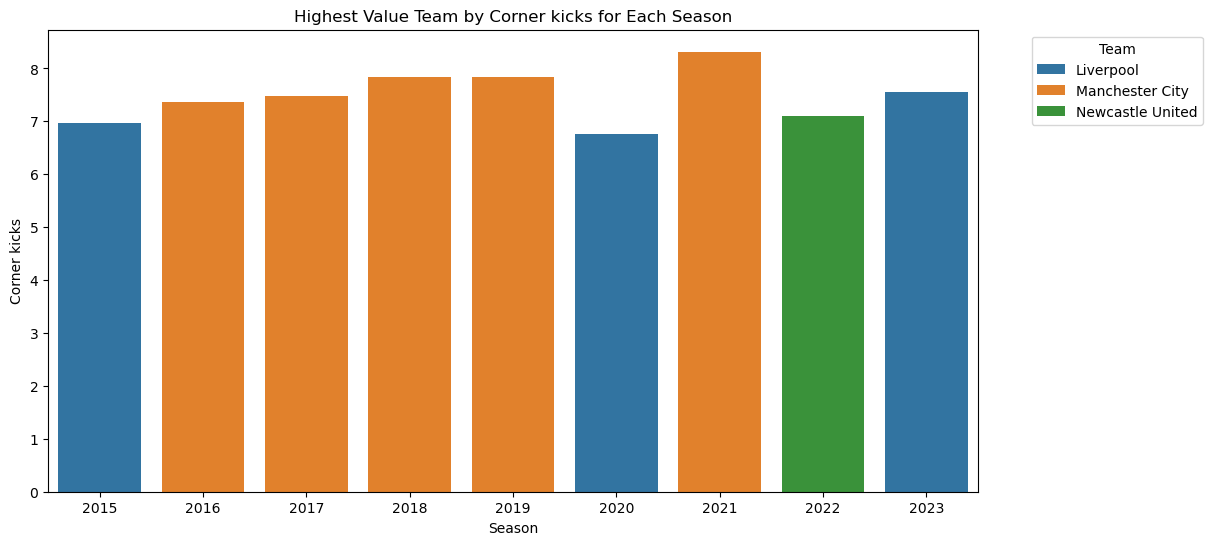

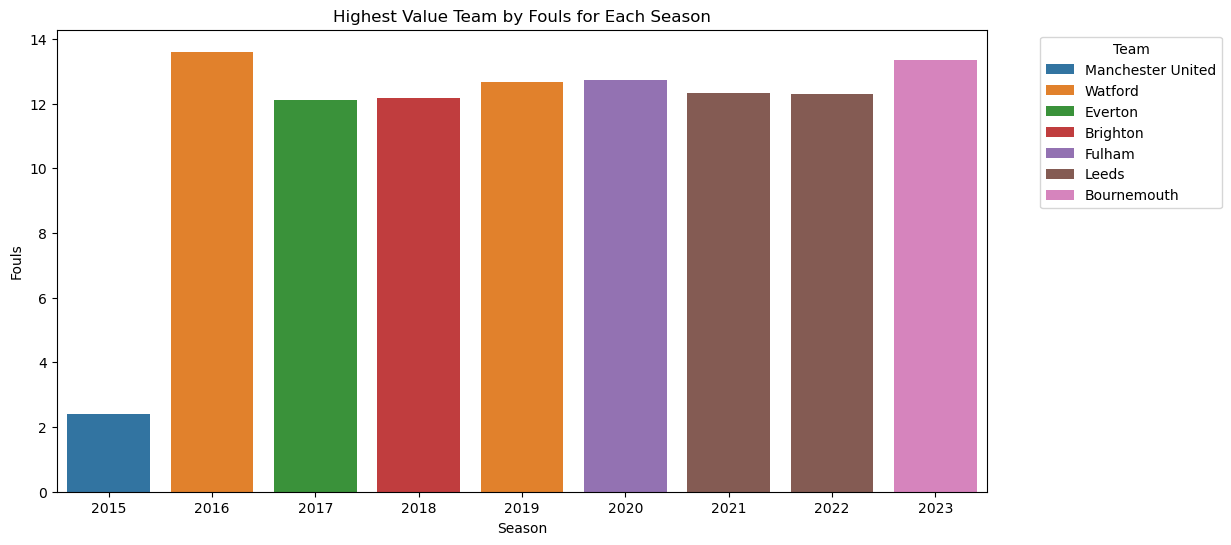

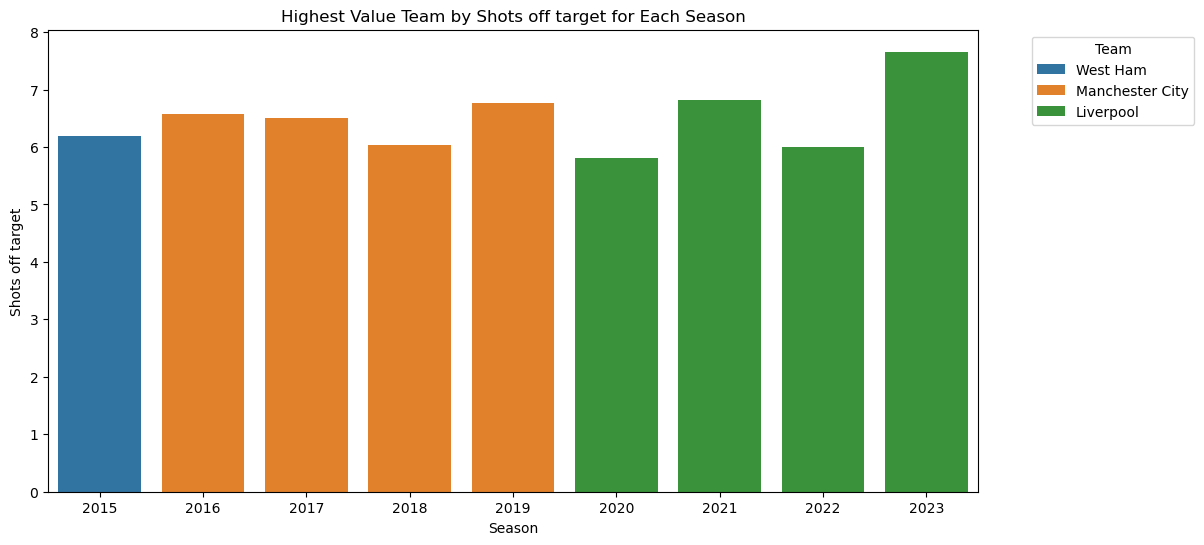

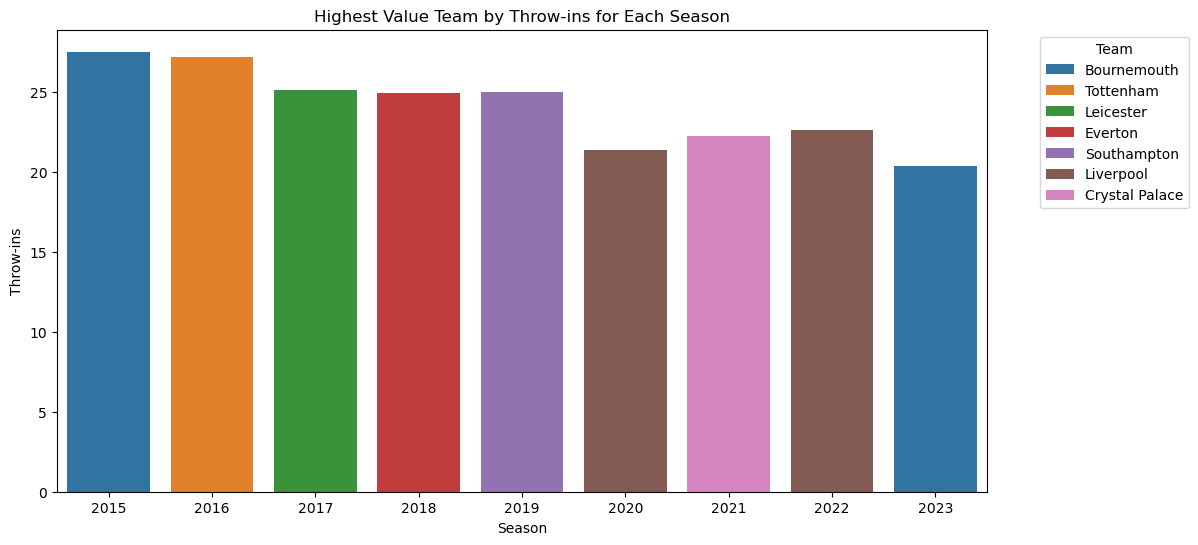

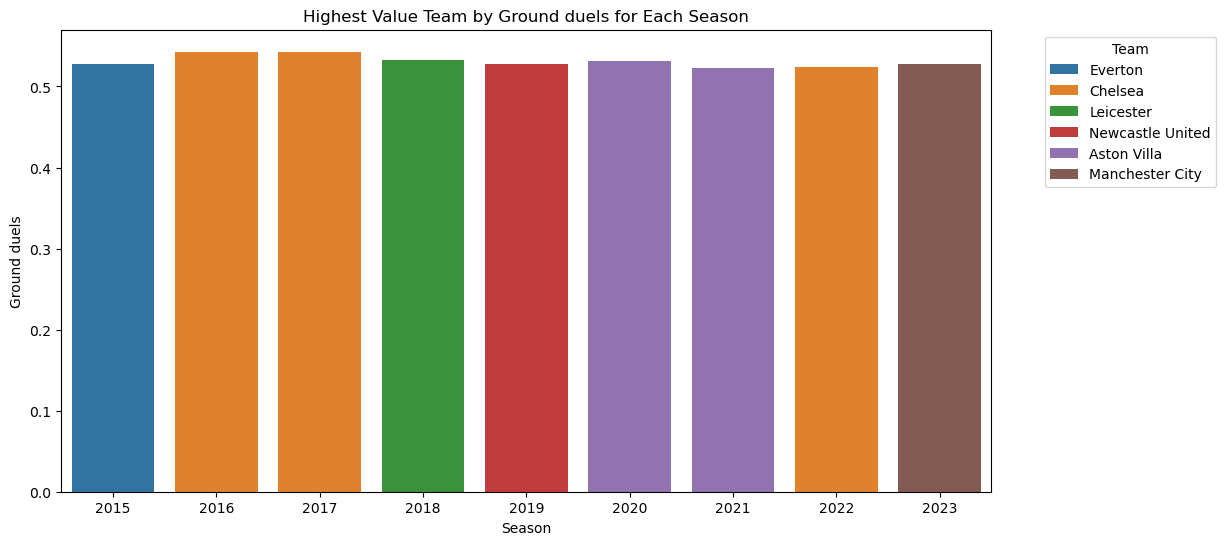

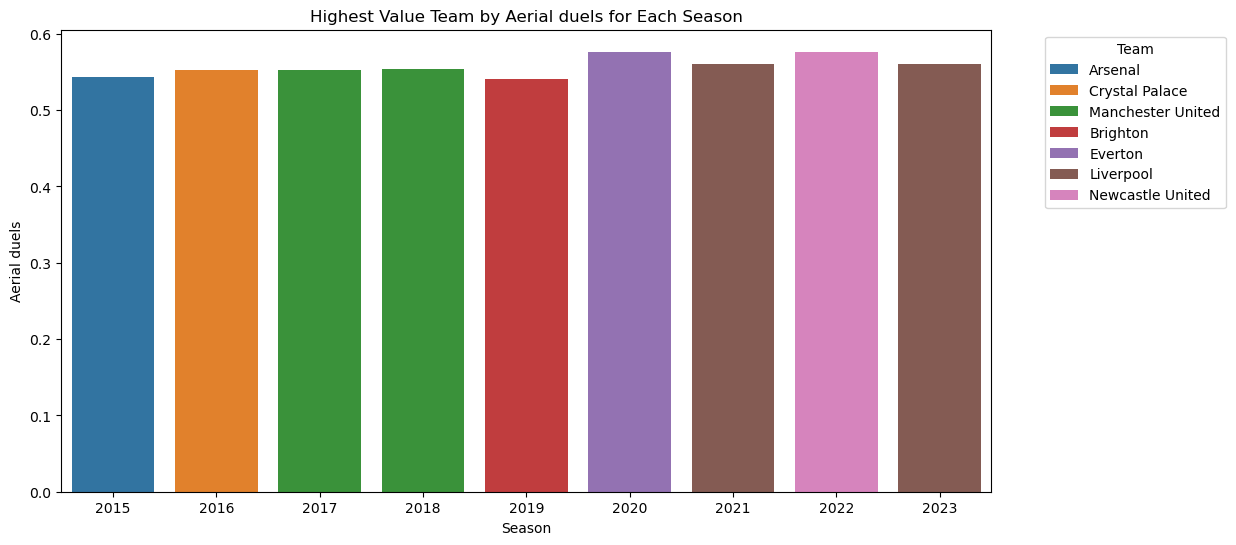

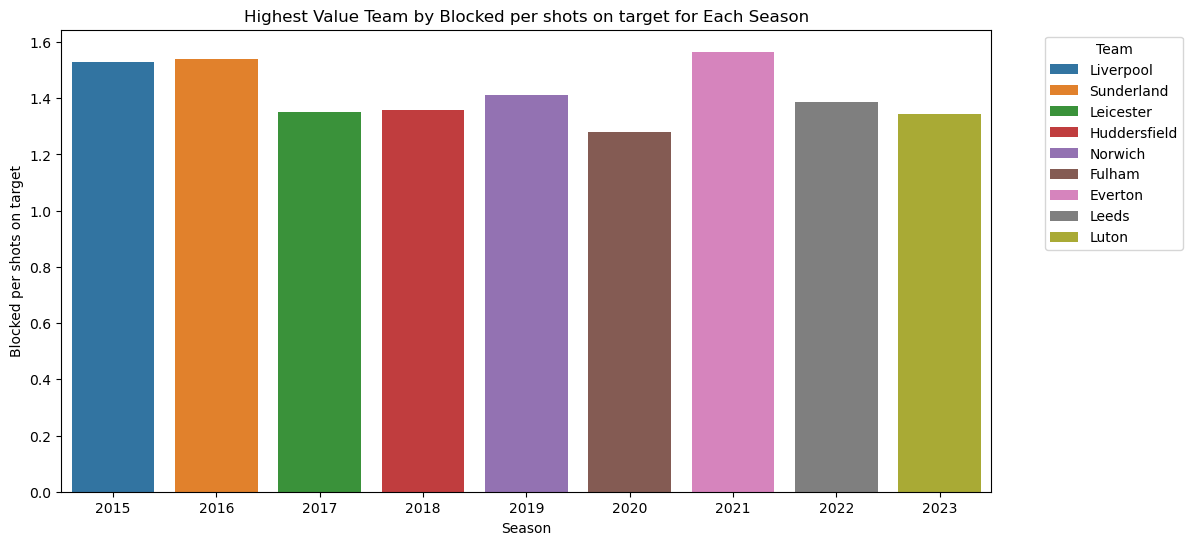

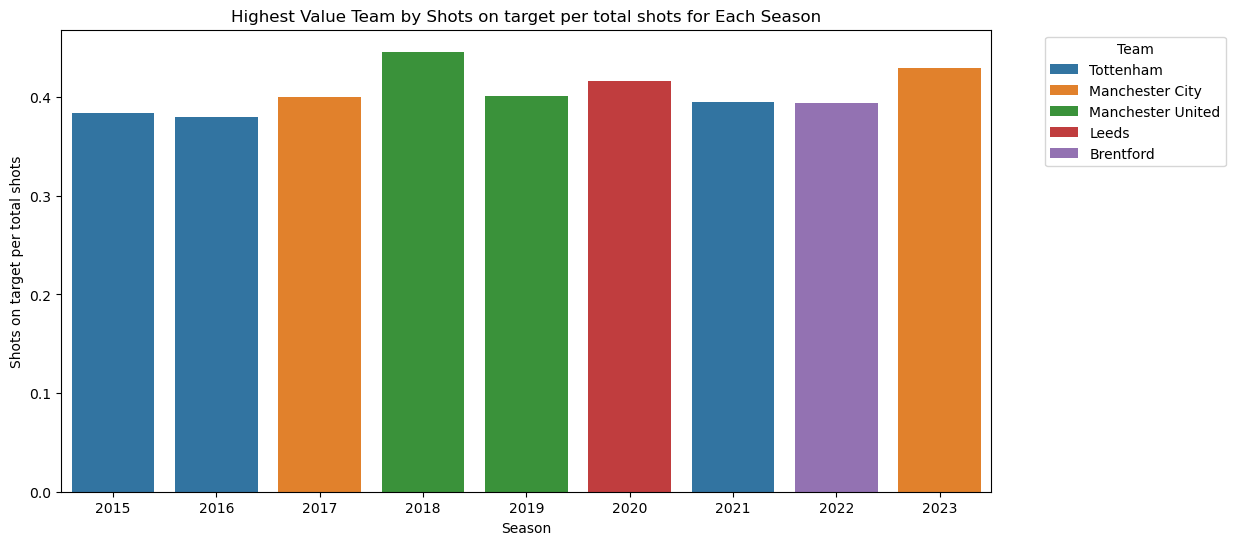

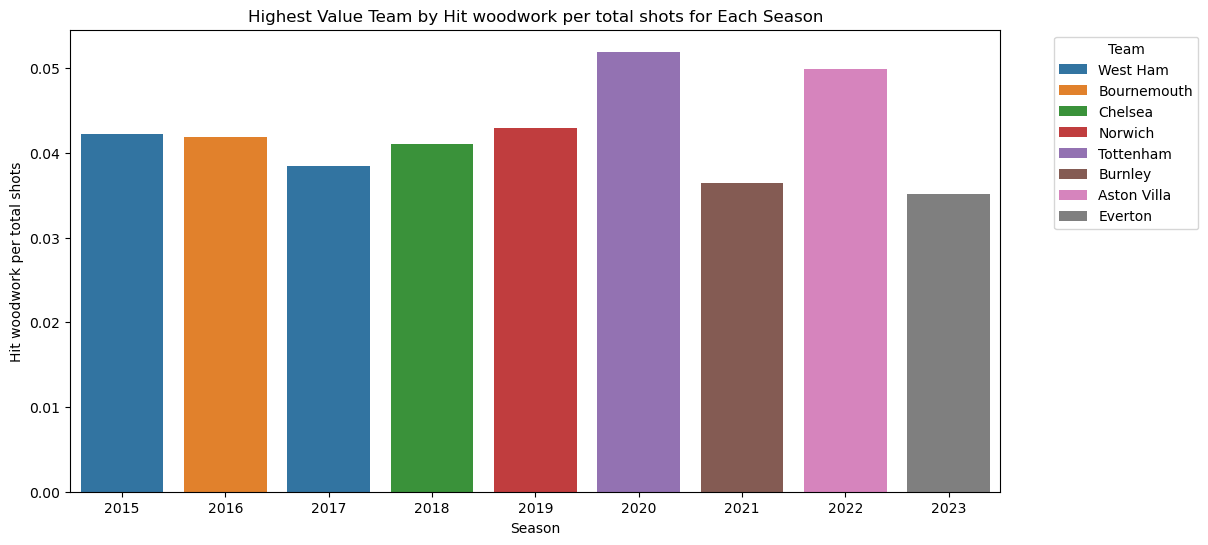

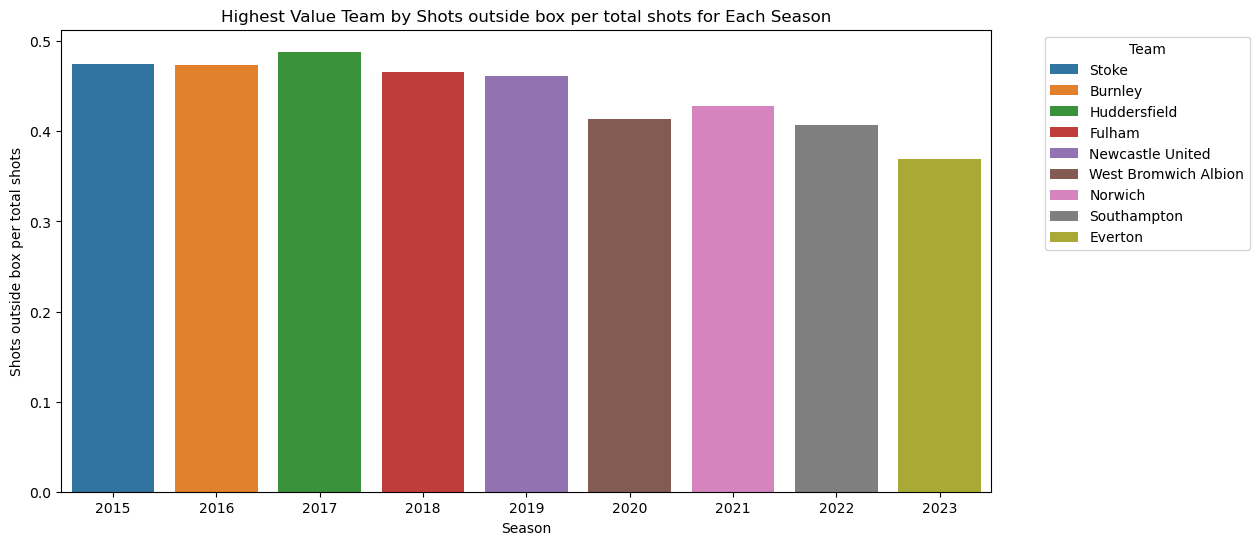

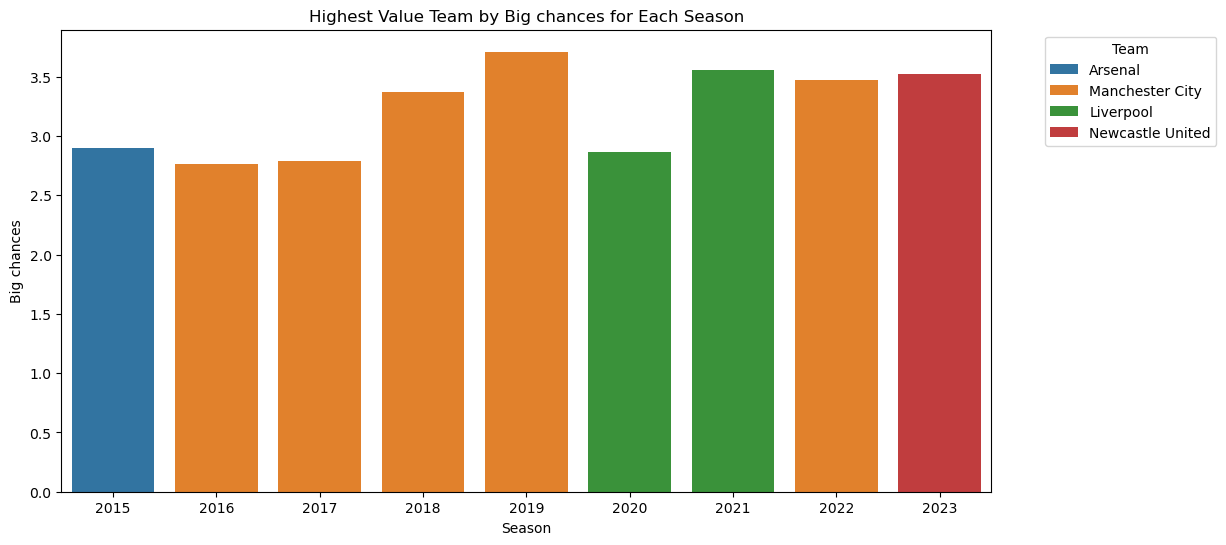

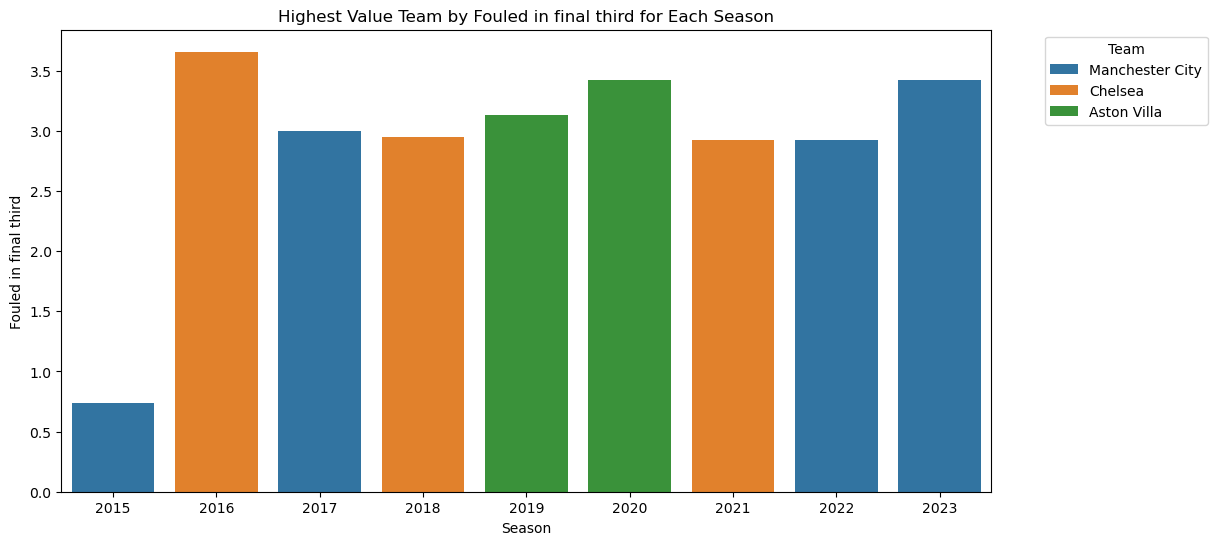

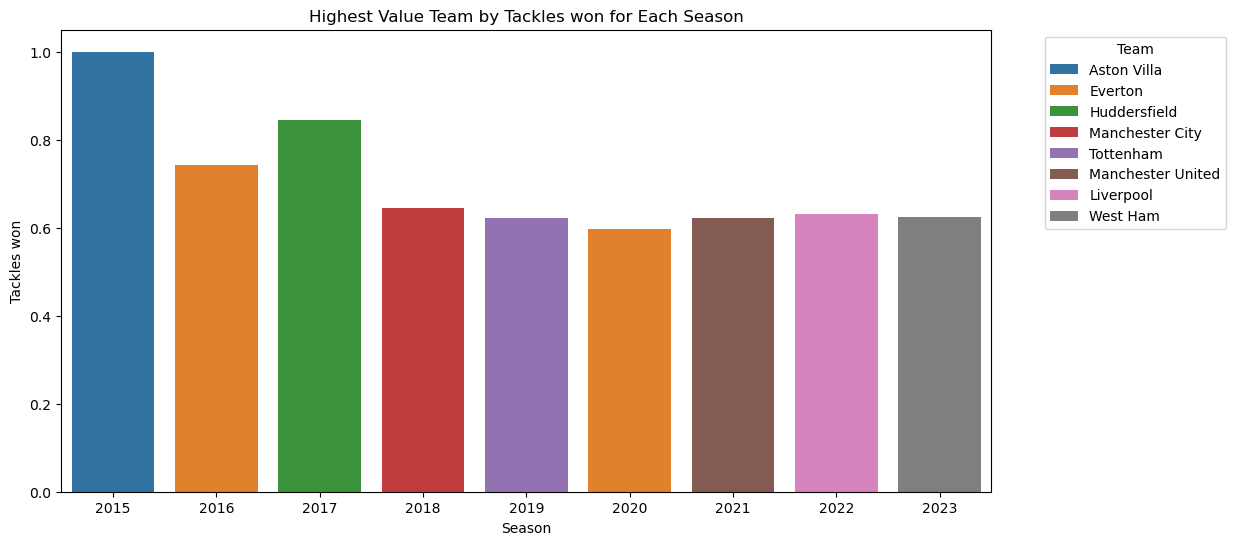

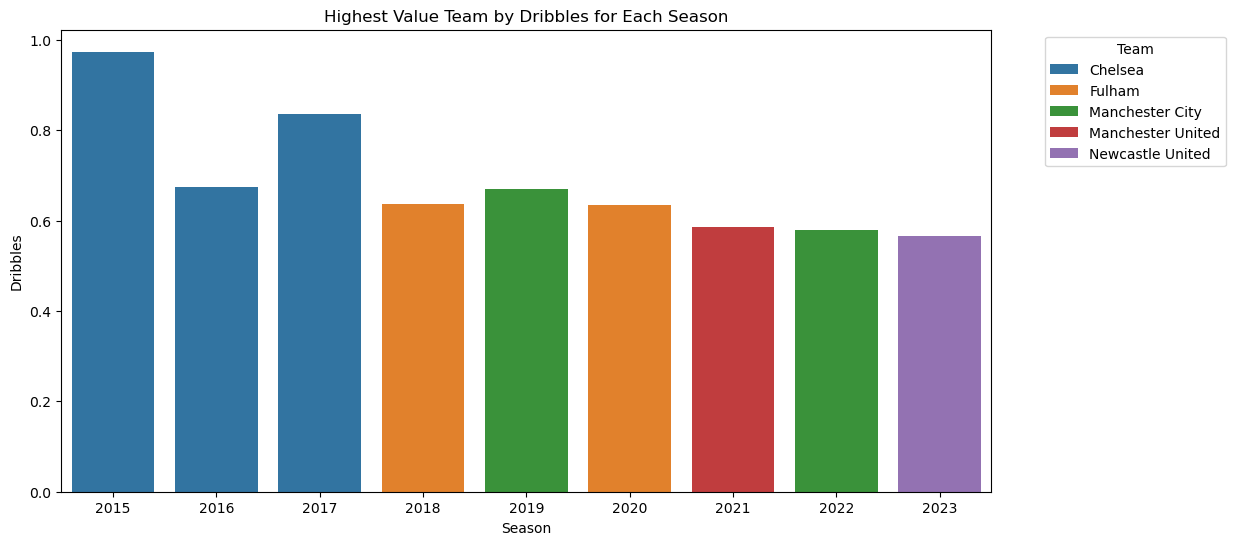

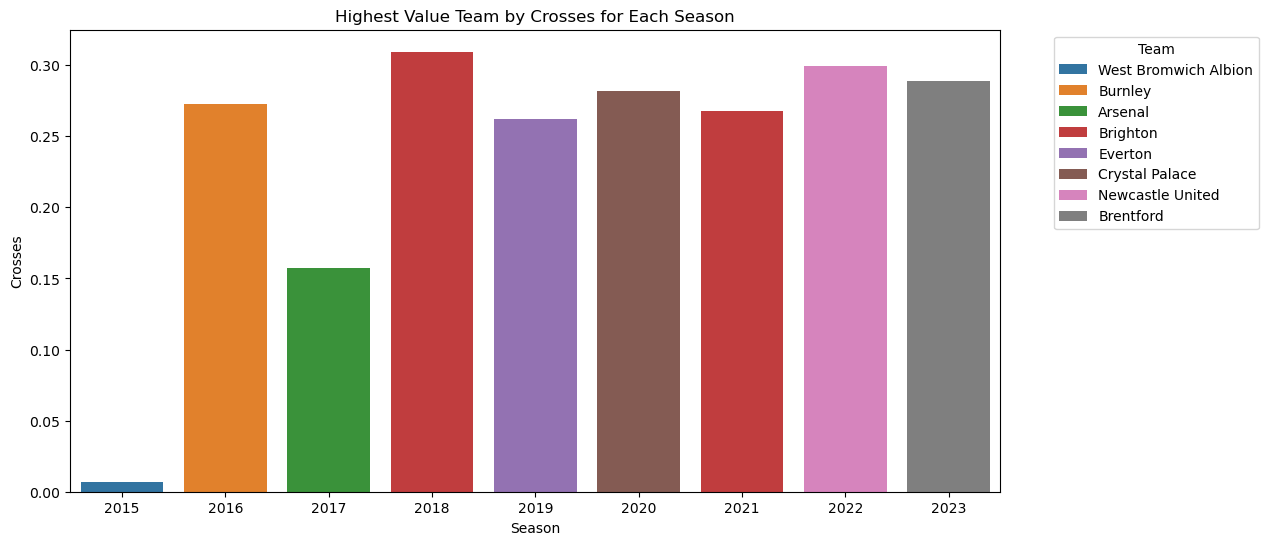

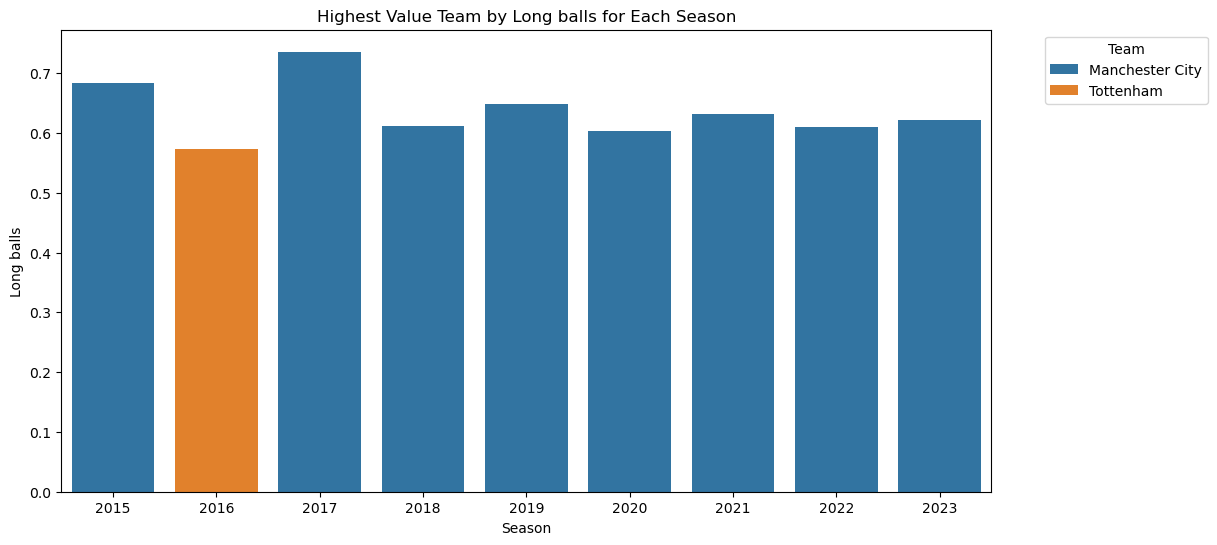

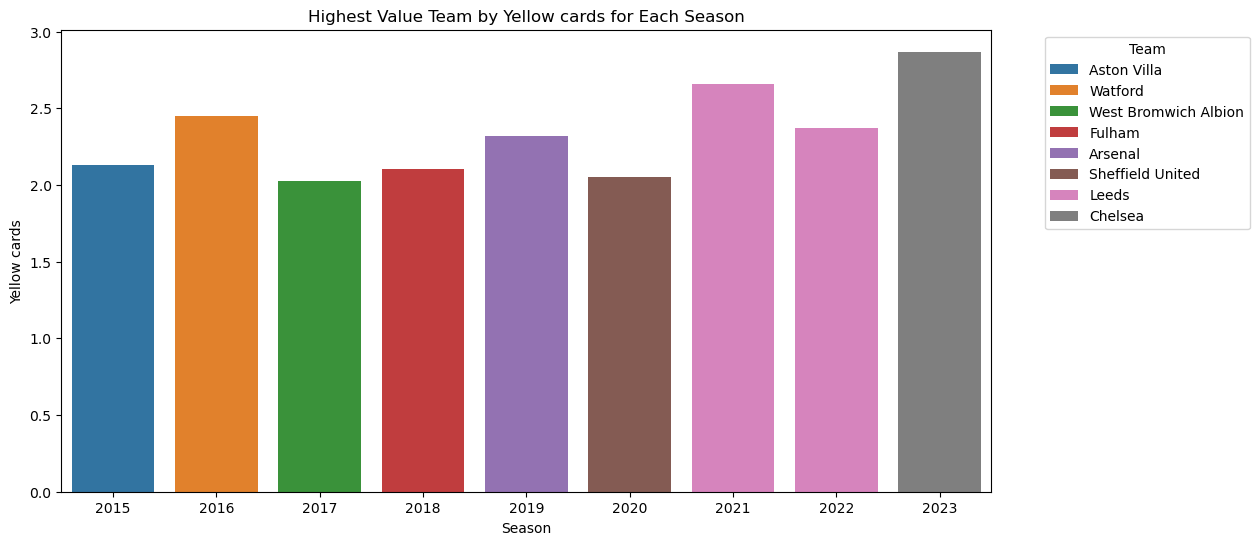

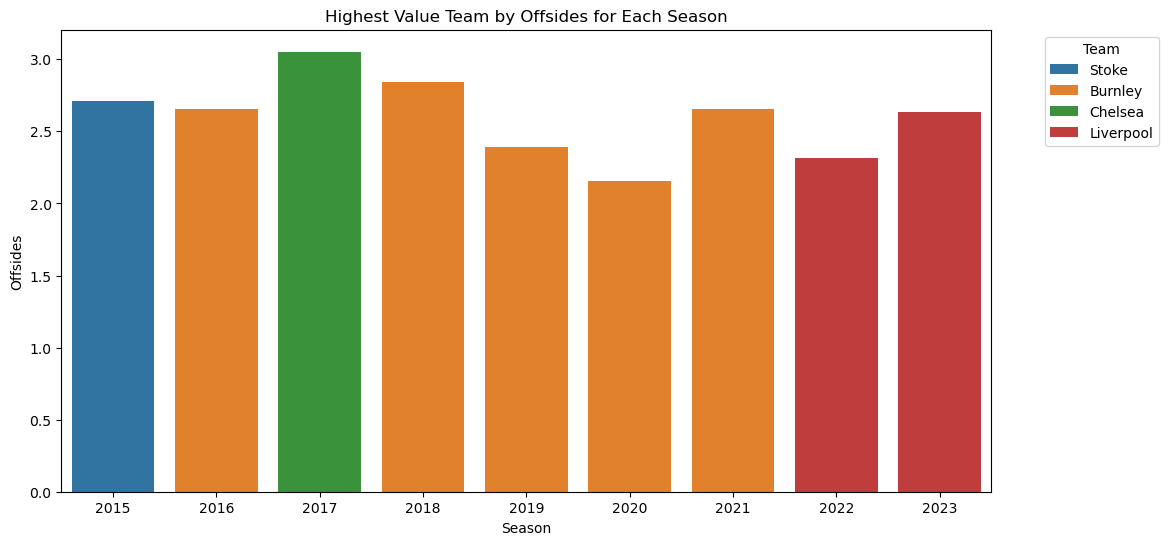

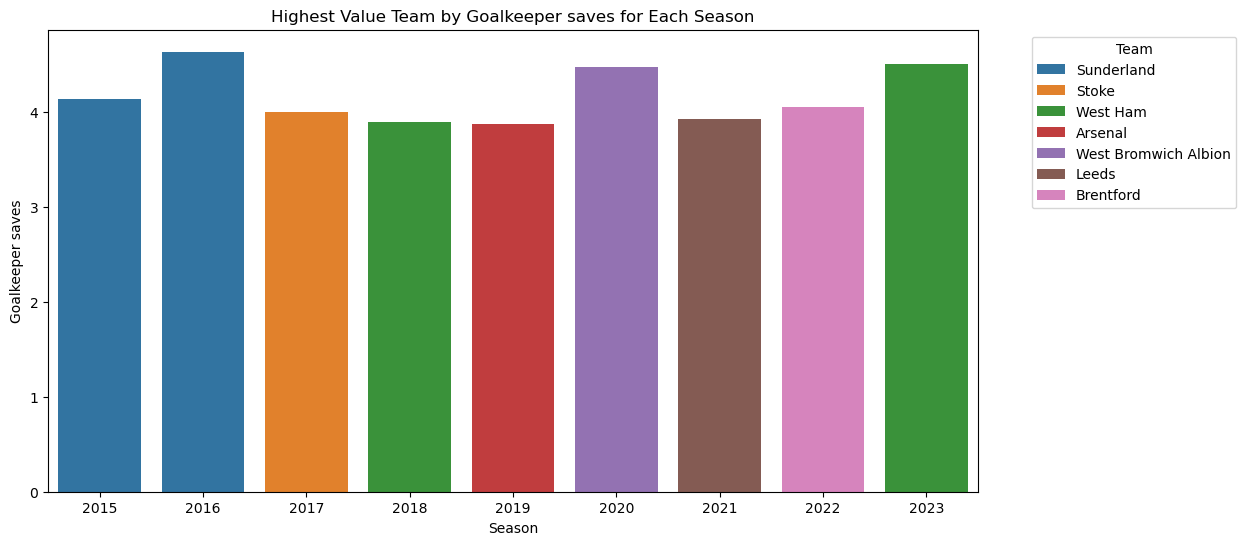

In [84]:
for feature in feature_list:
    plot_best_teams_by_feature(team_summaries_seasonal_df, season_list)

In [ ]:

# Plot the best team for every feature for every season
def plot_lowest_teams_by_feature(team_summaries_seasonal_df, season_list):
    team_feature_by_season = {}
    for season in season_list:
        best_team = team_summaries_seasonal_df[team_summaries_seasonal_df['season'] == season].sort_values(by=feature, ascending=True)
        best_team_name = best_team.iloc[0]['team_name']
        best_team_feature = best_team.iloc[0][feature]
        team_feature_by_season[season] = (best_team_name, best_team_feature)

    # Plotting x as season, y as feature with different colors for different teams
    seasons = list(team_feature_by_season.keys())
    feature_values = [team_feature_by_season[season][1] for season in seasons]
    team_names = [team_feature_by_season[season][0] for season in seasons]
    plt.figure(figsize=(12, 6))
    sns.barplot(x=seasons, y=feature_values, hue=team_names, dodge=False)
    plt.title(f'Highest Value Team by {feature} for Each Season')
    plt.xlabel('Season')
    plt.ylabel(feature)
    plt.legend(title='Team', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

    

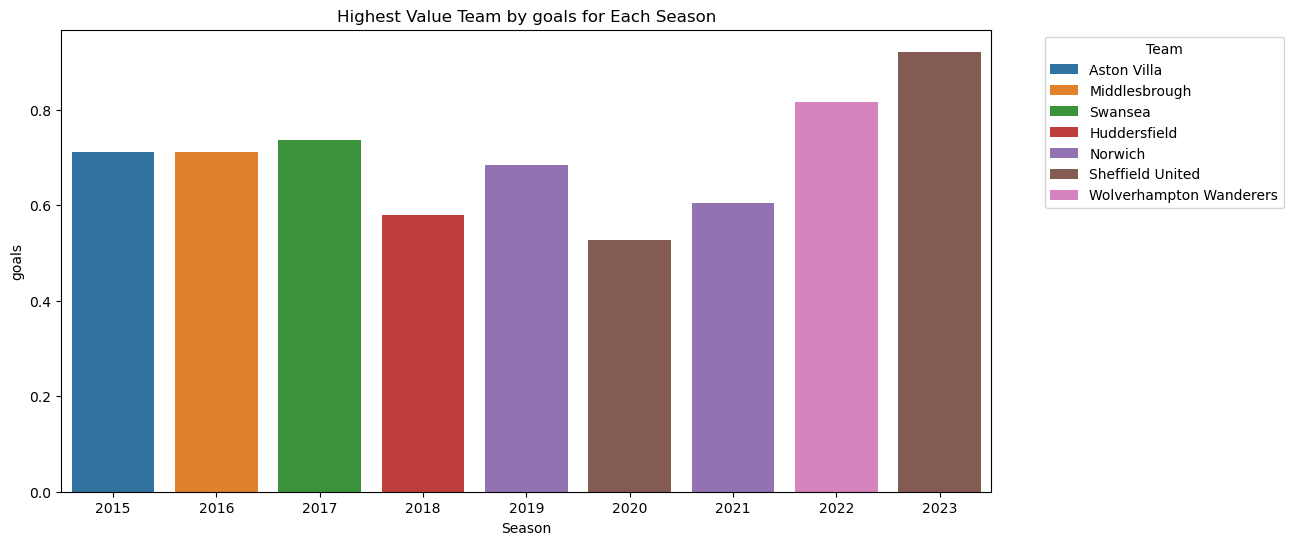

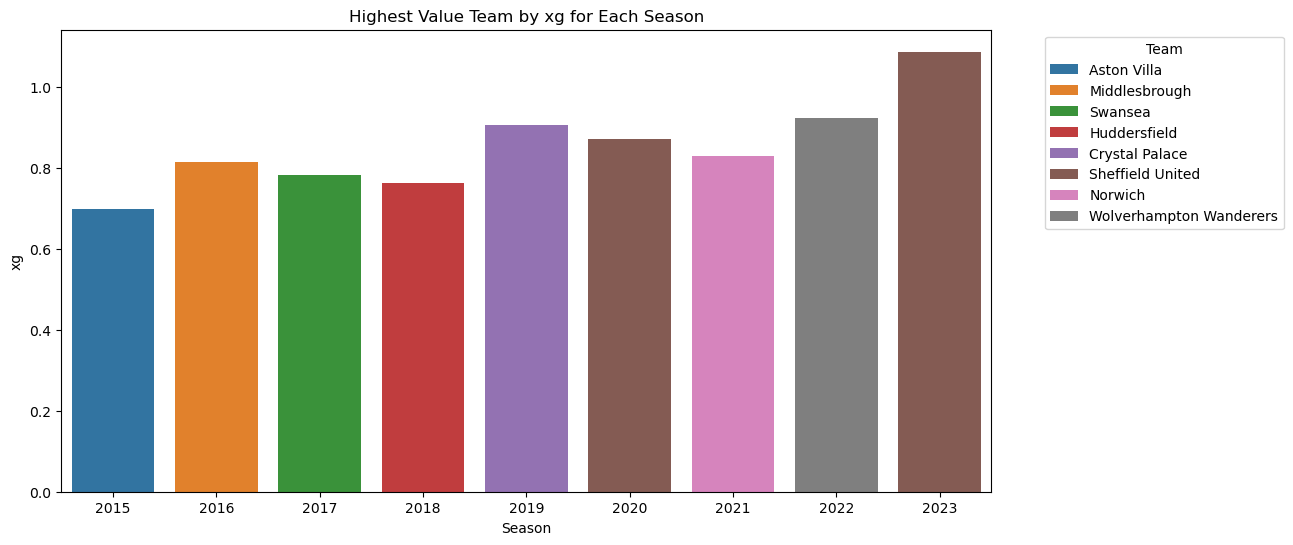

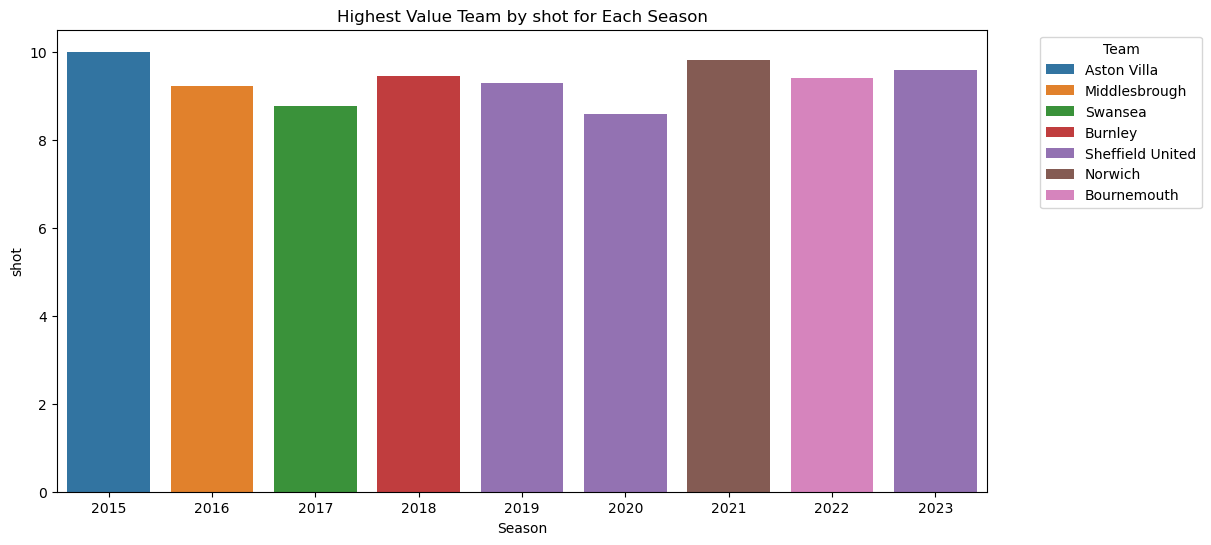

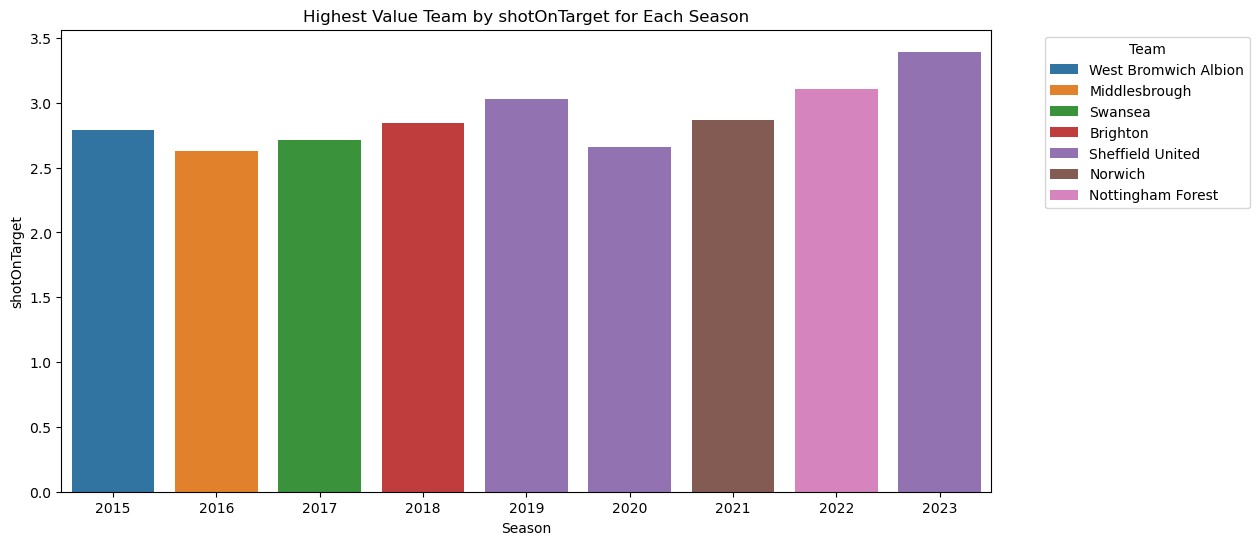

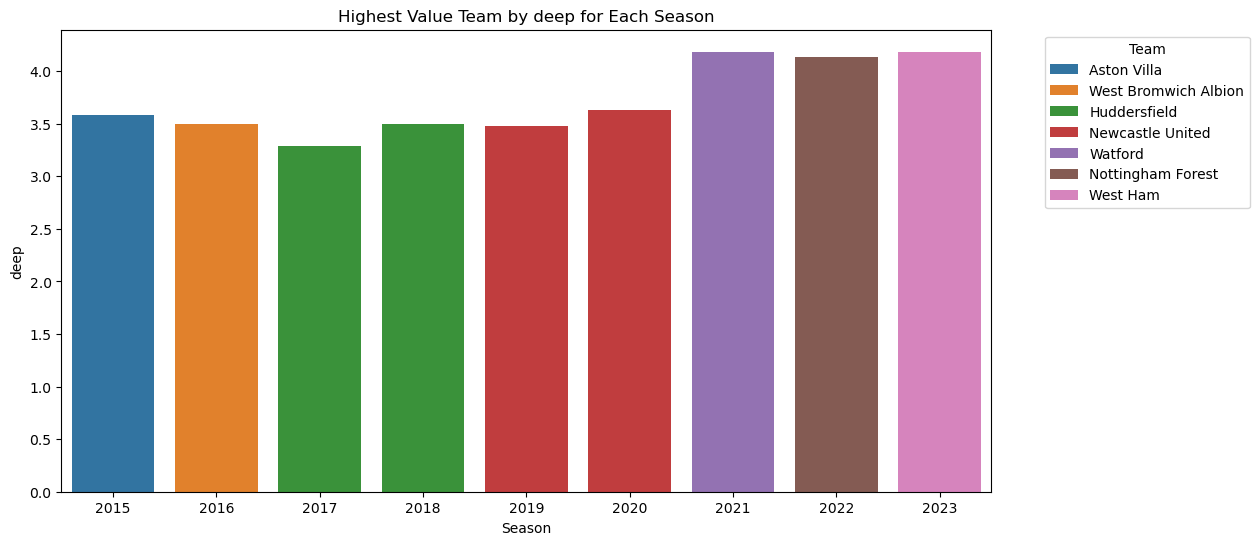

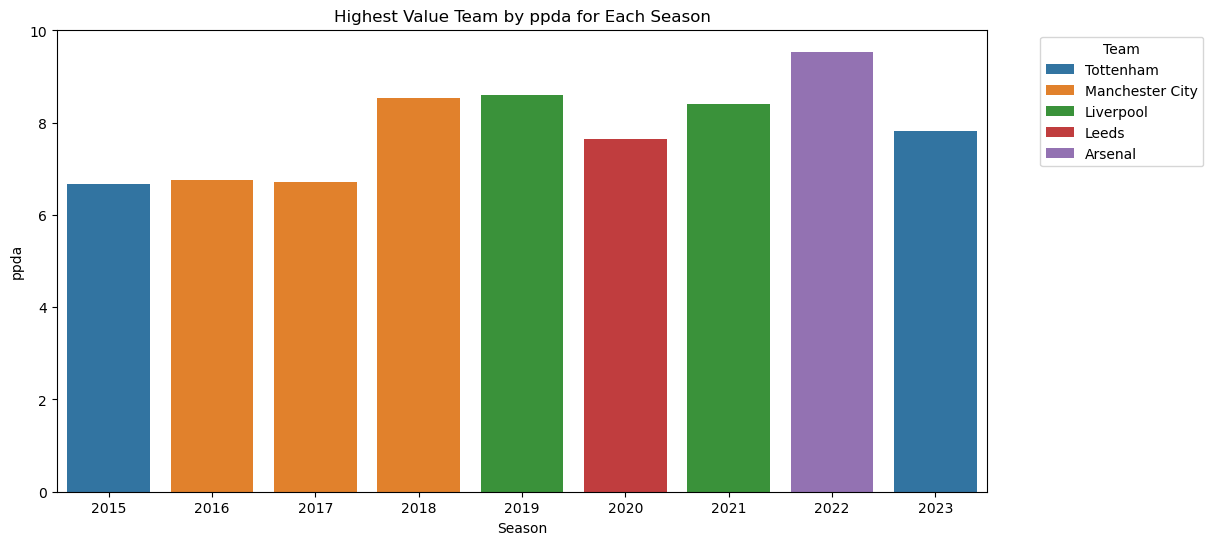

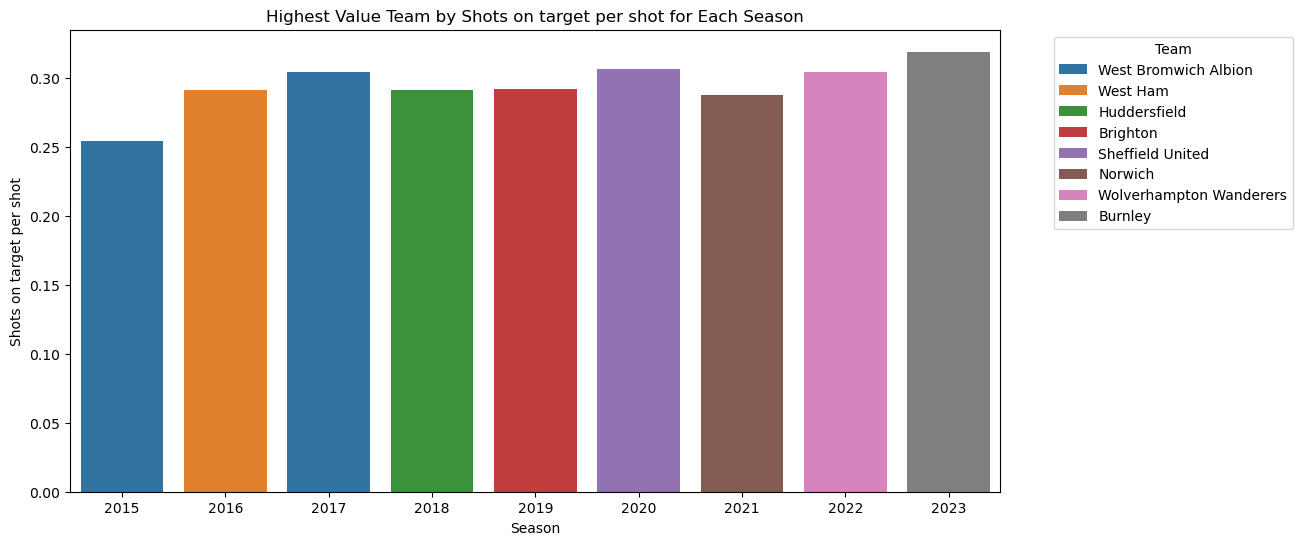

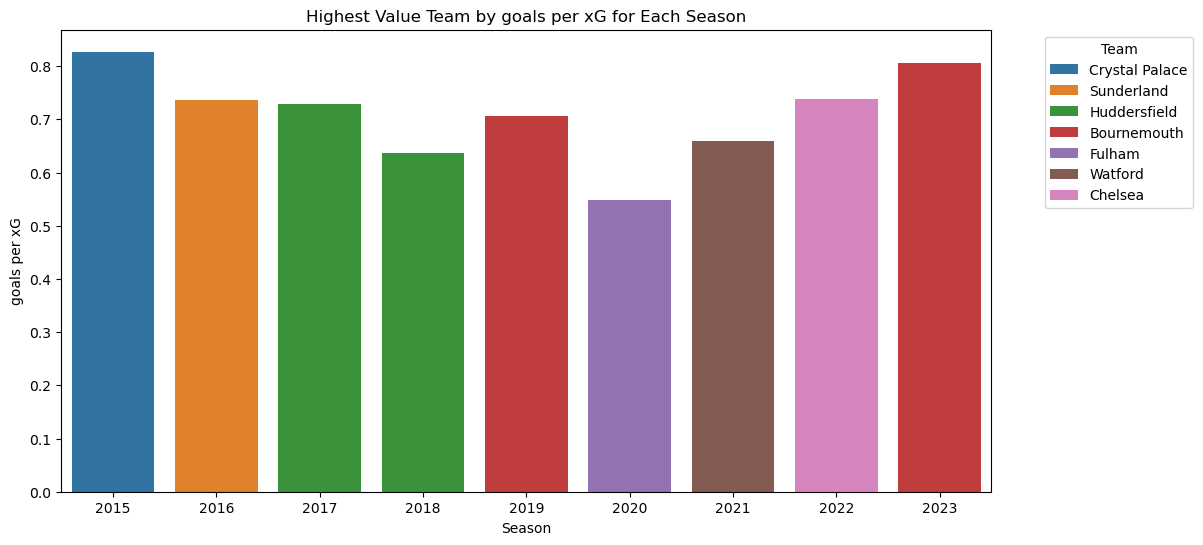

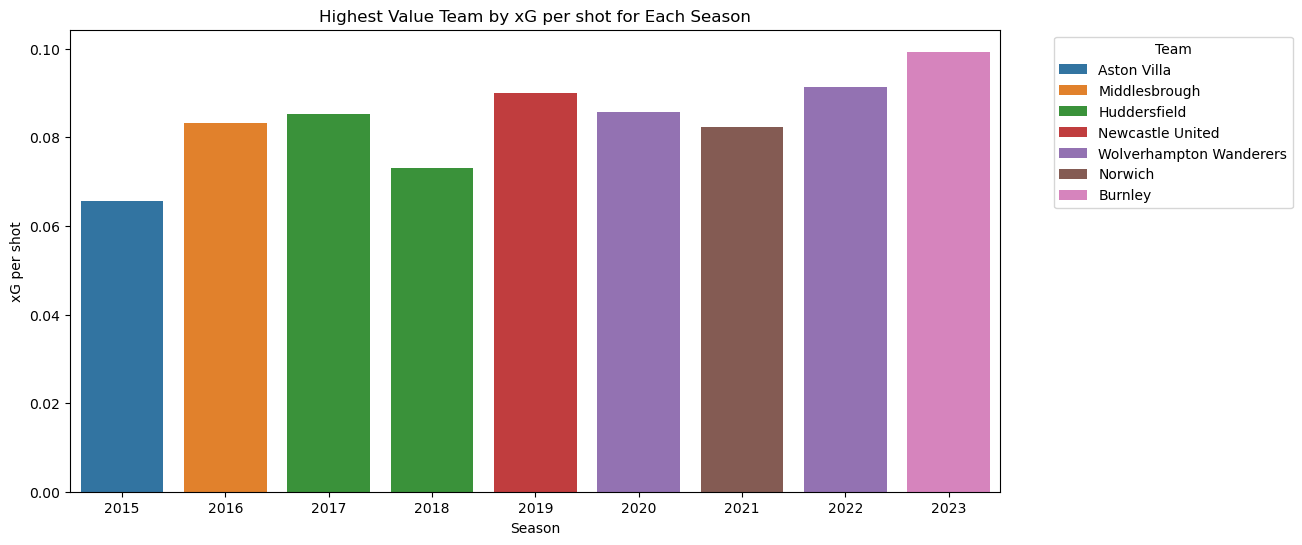

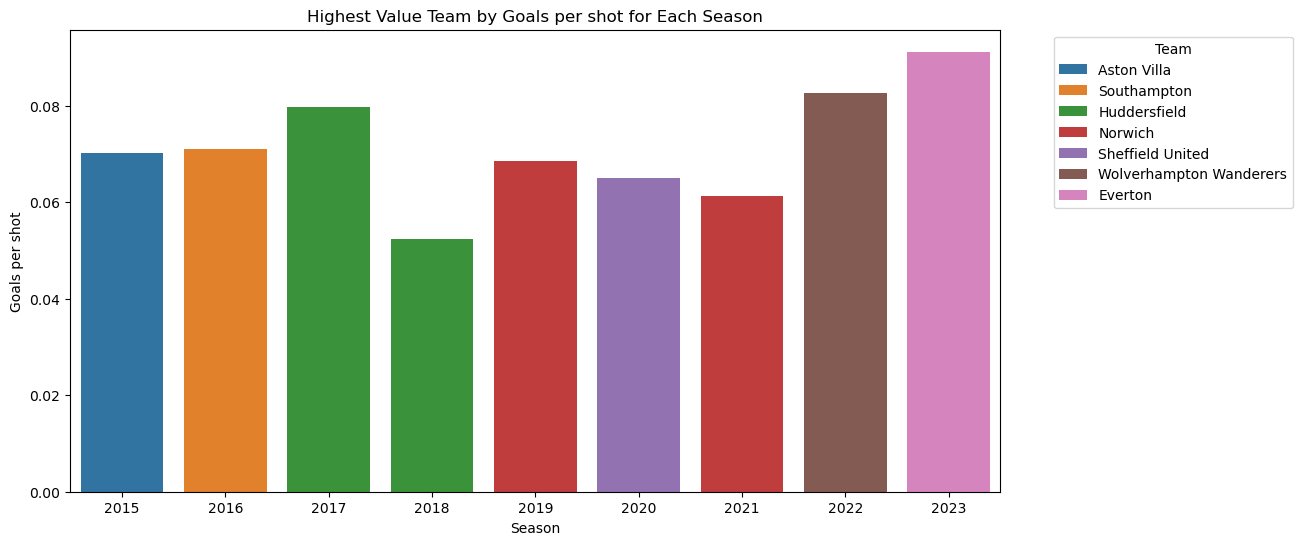

In [ ]:
for feature in feature_list:
    plot_lowest_teams_by_feature(team_summaries_seasonal_df, season_list)

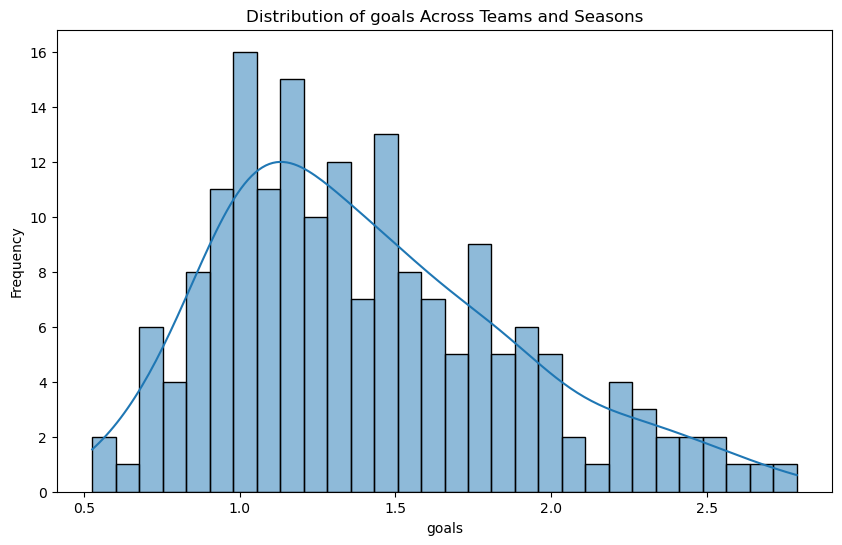

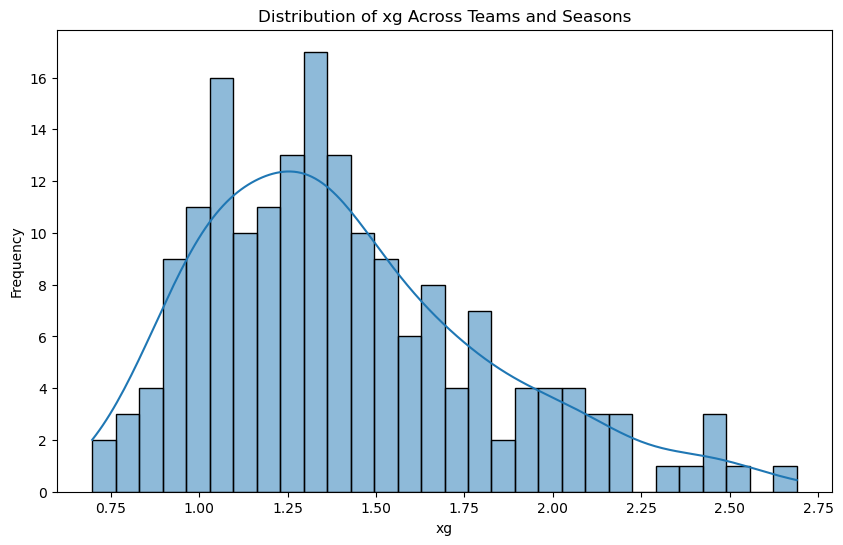

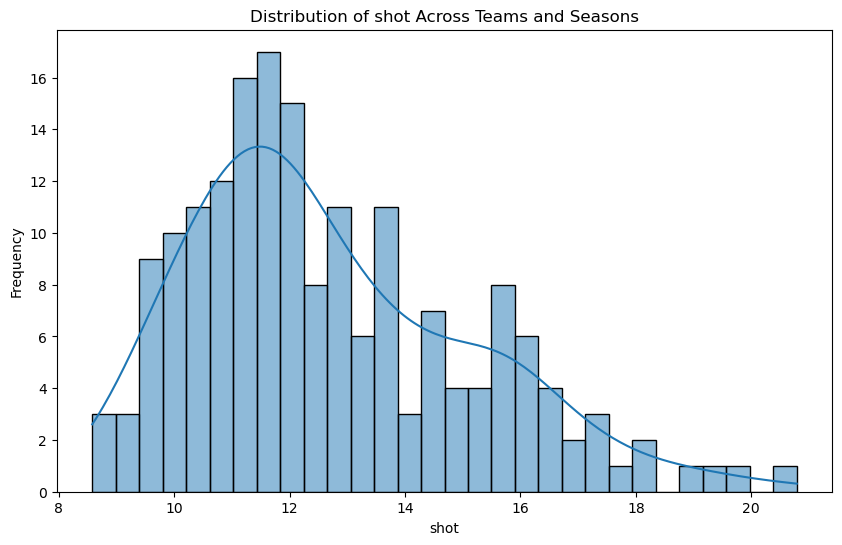

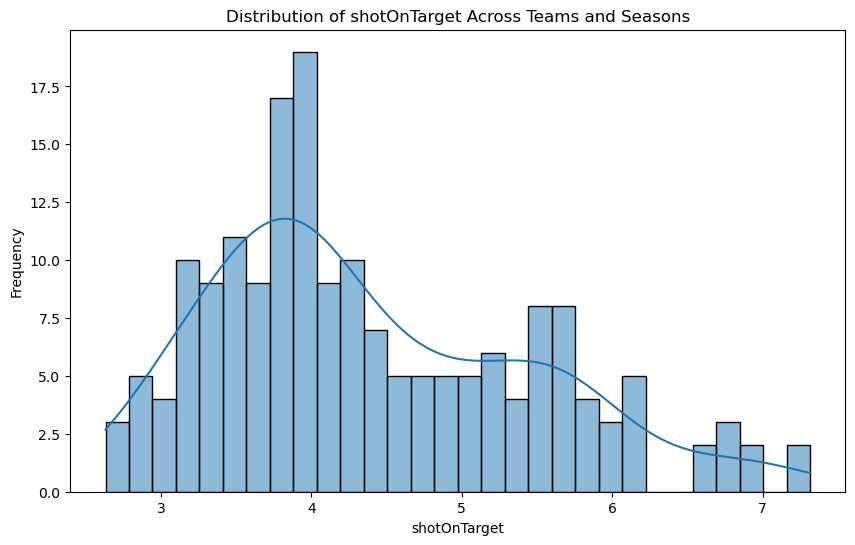

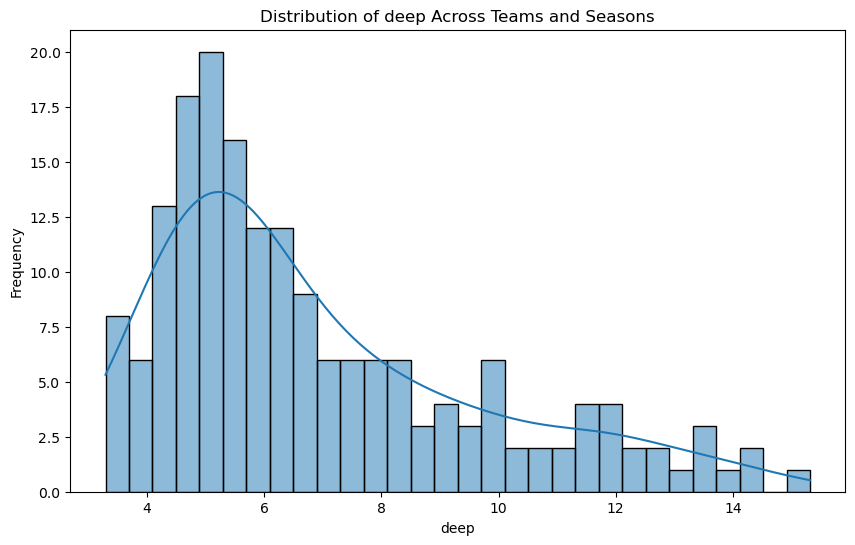

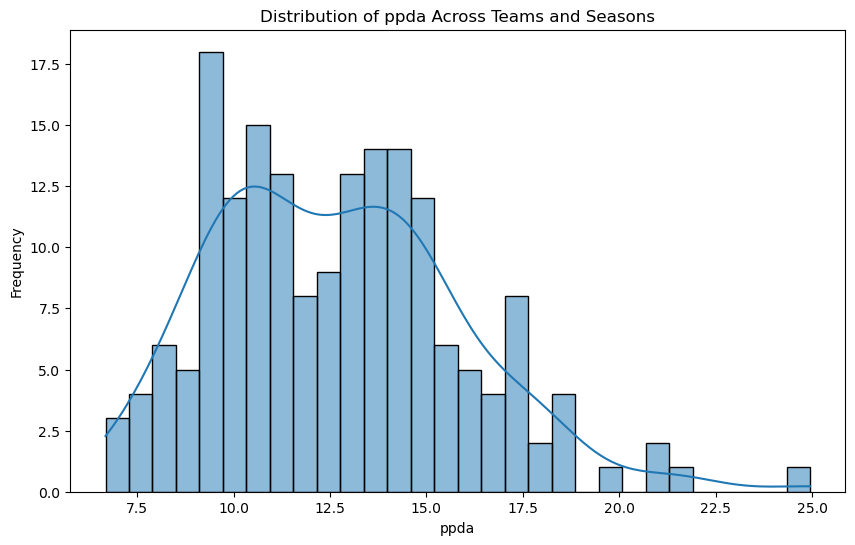

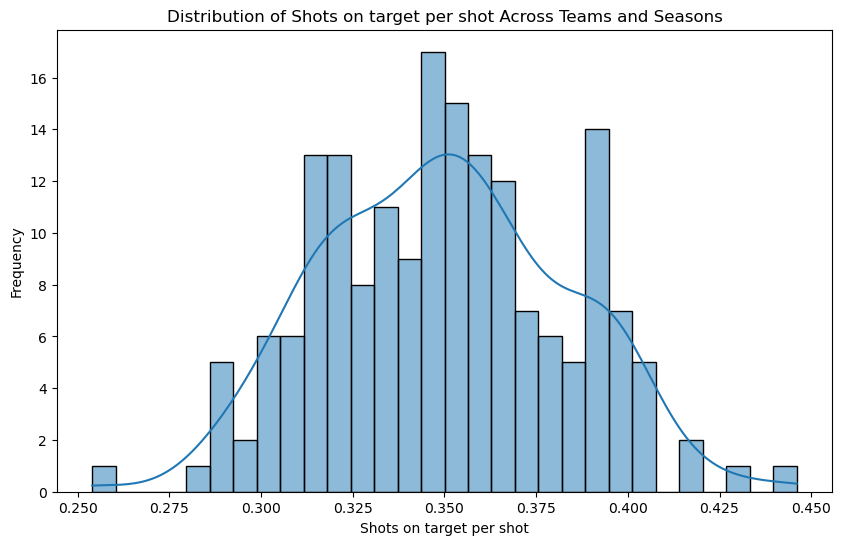

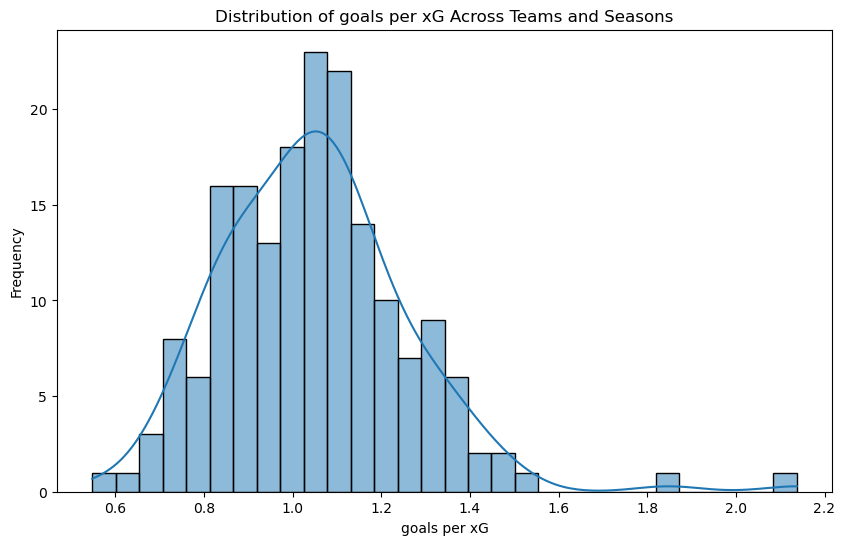

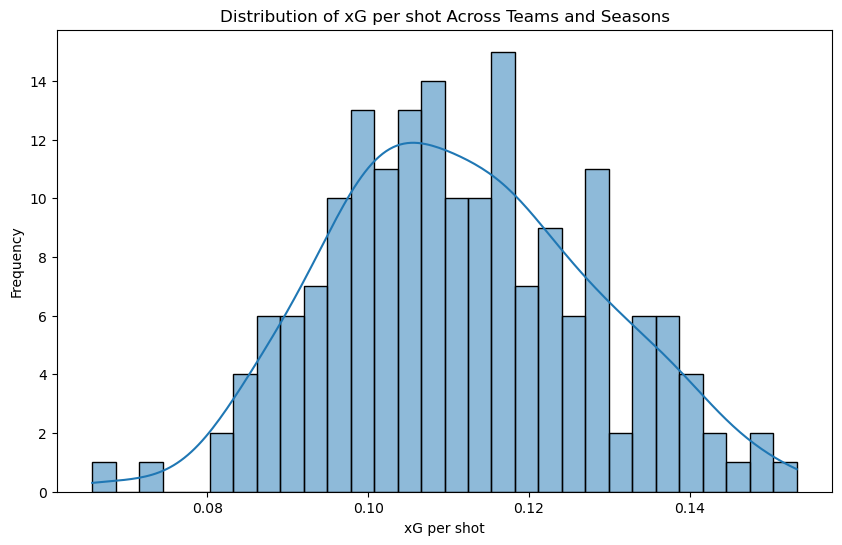

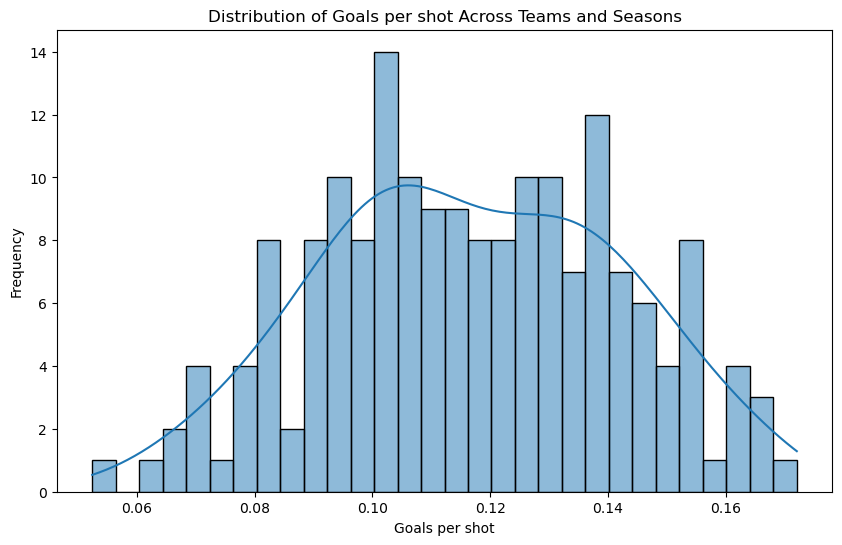

In [ ]:
# Plot distribution for each feature
for feature in feature_list:
    plt.figure(figsize=(10, 6))
    sns.histplot(team_summaries_seasonal_df[feature], bins=30, kde=True)
    plt.title(f'Distribution of {feature} Across Teams and Seasons')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()